## Remember how to use and adapt the gdal API to warp LPRD files into windsat grid (ED 0.25º) instead of EASEv2 25km

In [6]:
# imports
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

from osgeo import gdal, osr
import numpy as np
import os

In [9]:
# Open a windsat data file to corroborate coord system
windsat_template = "../../data/raw/daily_Windsat\RSS_WINDSAT_DAILY_TBTOA_MAPS_2017_09_10.nc"

ws_ds = xr.open_dataset(windsat_template, decode_times=False)
ws_ds

<xarray.Dataset>
Dimensions:         (longitude_grid: 1440, latitude_grid: 720, swath_sector: 2,
                     look_direction: 2, frequency_band: 5, polarization: 4,
                     polarization_dual: 2)
Dimensions without coordinates: longitude_grid, latitude_grid, swath_sector,
                                look_direction, frequency_band, polarization,
                                polarization_dual
Data variables: (12/34)
    longitude       (longitude_grid) float32 ...
    latitude        (latitude_grid) float32 ...
    node            (swath_sector) int32 ...
    look            (look_direction) int32 ...
    frequency_vpol  (frequency_band) float32 ...
    frequency_hpol  (frequency_band) float32 ...
    ...              ...
    colcld_WSAT     (latitude_grid, longitude_grid, swath_sector) float32 ...
    rain_IMERG      (latitude_grid, longitude_grid, swath_sector) float32 ...
    rain_WSAT       (latitude_grid, longitude_grid, swath_sector) float32 ...
    tran            (polarization_dual, frequency_band, latitude_grid, longitude_grid, look_direction, swath_sector) float32 ...
    tbup            (polarization_dual, frequency_band, latitude_grid, longitude_grid, look_direction, swath_sector) float32 ...
    tbdw            (polarization_dual, frequency_band, latitude_grid, longitude_grid, look_direction, swath_sector) float32 ...
Attributes: (12/72)
    Conventions:                            CF-1.7
    title:                                  RSS WindSat TOA Brightness Temper...
    version:                                V01.0
    summary:                                The dataset contains RSS WindSat ...
    references:                              [1] T. Meissner et al., Remote S...
    acknowledgement:                        Funded under NASA Grant 80NSSC21K...
    ...                                     ...
    Source_of_ancillary_IMERG_rain_rate:    Huffman, G. et al.,  2019. NASA G...
    Source_of_ancillary_CCMP_wind:          Mears, C. et al., 2023.Remote Sen...
    Source_of_ancillary_ERA5:               ECMWF Reanalysis v5 (ERA5). https...
    Source_of_RSS_WindSat_AS_ECV:           https://www.remss.com/missions/wi...
    Source_of_ancillary_HYCOM_SSS:          Hybrid Coordinate Ocean Model, Gl...
    Source_of_WindSat_L1C_TB:               T. Meissner et al., Remote Sensin...

In [ ]:
from osgeo import gdal, osr

input_file = r"../..\data\raw\AMSRU_Mland_2017365D.tif"
dataset = gdal.Open(input_file)

projection = dataset.GetProjection()
# geotransform = dataset.GetGeoTransform()

# Reading the geostransform from the dataset results in some inconsistencies in the decimal places. This is taken from https://nsidc.org/data/user-resources/help-center/guide-ease-grids EASEv2 25km
geotransform = (-17334193.54, 25067.53, 0.0, 7344784.83, 0.0, -25067.53)

# TODO: Specify the Geoid in this projections.
source_srs = osr.SpatialReference()
source_srs.ImportFromEPSG(3410)

target_srs = osr.SpatialReference()
target_srs.ImportFromEPSG(4326)

transform = osr.CoordinateTransformation(source_srs, target_srs)

output_file = r"../../data/output/reprojected_resampled_v1.tif"
driver = gdal.GetDriverByName("GTiff")

# Define output dimensions based on desired shape (584, 1388)
# Define the output grid parameters
output_width = 1440  
output_height = 720  

# # Define output geotransform based on desired resolution (25km)
# output_geotransform = (geotransform[0], x_res, 0, geotransform[3], 0, y_res)
output_geotransform = (-180.0, 0.25, 0.0, 90.0, 0.0, -0.25)  # (UL corner, pixel size)


# Create the output dataset with the desired shape and geotransform
output_dataset = driver.Create(output_file, output_width, output_height, dataset.RasterCount, gdal.GDT_Float32)
output_dataset.SetProjection(target_srs.ExportToWkt())
output_dataset.SetGeoTransform(output_geotransform)

# Reproject and resample using gdal.Warp()
gdal.Warp(output_dataset, dataset, dstSRS=target_srs.ExportToWkt(), width=output_width, height=output_height, resampleAlg=gdal.GRA_Bilinear)

# Close the files
dataset = None
output_dataset = None


In [3]:
# Re-do the function that I use in the script and modify it according to this.

In [ ]:

def reproject_file(file_path: str, output_folder: str = None) -> bool:
    """
        Read the input geotiff in EASE v1
        Reproject + resample into ED 0.25º
        create latitude an longitude bands for convenience.
        (bands added as second to last, and last band respectively)

        param output_folder: name of the new file to save reprojected data.
            If None, data will be ovewritten in file_path.

        Returns bool: whether or not the file was succesfully reprojected
    """
    dataset = gdal.Open(file_path)

    # Define the geotransform for the output dataset
    target_geotransform = (-180.0, 0.25, 0.0, 90.0, 0.0, -0.25)

    output_width = 1440
    output_height = 720

    # Define src and geotransform from the input:
    source_srs = osr.SpatialReference()
    source_srs.ImportFromEPSG(3410)

    # Desired projection
    target_srs = osr.SpatialReference()
    target_srs.ImportFromEPSG(4326)

    # NOTE: target is now geo corrdinates, we dont need this
    # # Inverse transformation to geographic coordinates (to add lon & lat)
    # geo_srs = osr.SpatialReference()
    # geo_srs.ImportFromEPSG(4326)  # WGS 84
    # inverse_transform = osr.CoordinateTransformation(target_srs, geo_srs)

    # Declare the output file and driver:
    driver = gdal.GetDriverByName("GTiff")

    if output_folder is None:
        output_file = os.path.join(os.path.dirname(file_path), "temp.tif")

    else:
        output_file = os.path.join(output_folder, os.path.basename(file_path))

    # Create the new dataset. NOTE: removed +2 raster count, lat and lon
    output_dataset = driver.Create(
        output_file, output_width, output_height,
        dataset.RasterCount,  #+ 2,
        gdal.GDT_Float32
    )
    output_dataset.SetProjection(target_srs.ExportToWkt())
    output_dataset.SetGeoTransform(target_geotransform)

    # Set the output dataset value to -999.0, instead of 0.
    for i in range(1, output_dataset.RasterCount, 1):
        band = output_dataset.GetRasterBand(i)
        arr = band.ReadAsArray()
        arr = arr - 999.0
        band.WriteArray(arr)

    # Reproject and resample using gdal.Warp()
    gdal.Warp(
        output_dataset,
        dataset,
        dstSRS=target_srs.ExportToWkt(),
        width=output_width,
        height=output_height,
        resampleAlg="near",
        # GRA_Bilinear TODO: bilinear warp does not work with Nodata params,
        # there will be values between -999 and the valid range
        srcNodata=float(-999.0),
        dstNodata=-999.0,
    )

    # # Create bands for latitude and longitude
    # lat_band = output_dataset.GetRasterBand(dataset.RasterCount + 1)
    # lon_band = output_dataset.GetRasterBand(dataset.RasterCount + 2)

    # # Create arrays for latitude and longitude
    # lat_array = np.zeros((output_height, output_width), dtype=np.float32)
    # lon_array = np.zeros((output_height, output_width), dtype=np.float32)

    # Calculate latitude and longitude for each pixel
    # for y in range(output_height):
    #     for x in range(output_width):
    #         pixel_x = target_geotransform[0] + x * target_geotransform[1] + y * target_geotransform[2]
    #         pixel_y = target_geotransform[3] + x * target_geotransform[4] + y * target_geotransform[5]
            # lon, lat, _ = inverse_transform.TransformPoint(pixel_x, pixel_y)
            # lat_array[y, x] = lat
            # lon_array[y, x] = lon

    # # Write the latitude and longitude arrays
    # lat_band.WriteArray(lat_array)
    # lon_band.WriteArray(lon_array)

    # # Set descriptions
    # lat_band.SetDescription('Latitude')
    # lon_band.SetDescription('Longitude')

    # Close the files
    dataset = None
    output_dataset = None

    if output_folder is None:
        # Delete original file, rename temp file.
        os.remove(file_path)
        os.rename(output_file, file_path)

    return True

In [8]:
file_path = r"../..\data\raw\AMSRU_Mland_2017365D.tif"
output_folder = r"../../data\processed"
reproject_file(
    file_path=file_path,
    output_folder=output_folder,
)

c:\Users\andre\Desktop\VS_Code\PMW_LST\.conda\Lib\site-packages\osgeo\gdal.py:312: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


True

# Test this with a single file to check that it works

In [11]:
# Open the reprojected file and a windsat file to check that they match
reprojected_filepath = "../../data\processed\AMSRU_Mland_2017365D.tif"
rp_ds = xr.open_dataset(reprojected_filepath)
rp_ds

<xarray.Dataset>
Dimensions:      (band: 9, x: 1440, y: 720)
Coordinates:
  * band         (band) int32 1 2 3 4 5 6 7 8 9
  * x            (x) float64 -179.9 -179.6 -179.4 -179.1 ... 179.4 179.6 179.9
  * y            (y) float64 89.88 89.62 89.38 89.12 ... -89.38 -89.62 -89.88
    spatial_ref  int32 ...
Data variables:
    band_data    (band, y, x) float32 ...

### It looks good, represent it with the coastline to check that it matches, I can also open it in QGIS

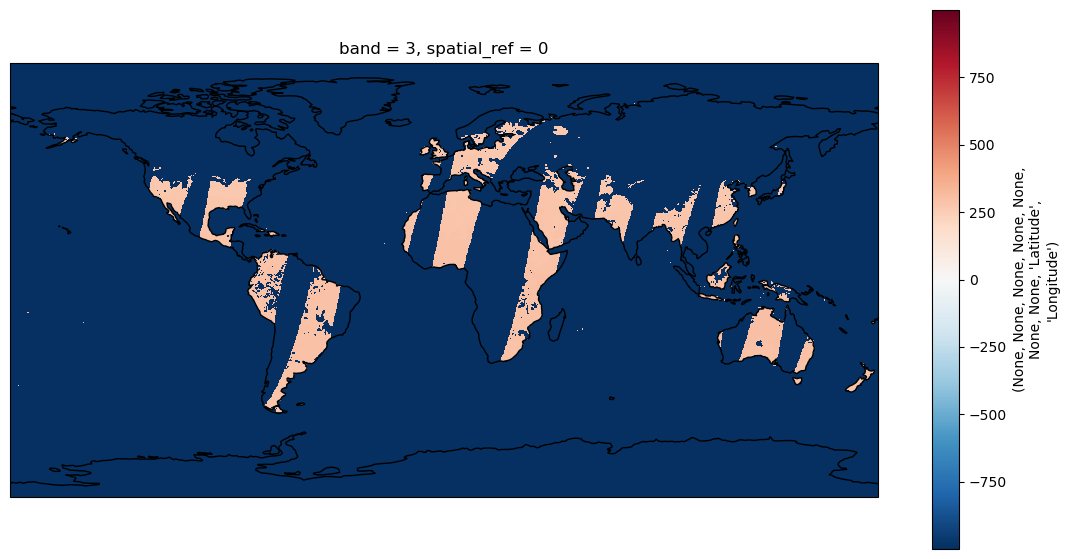

In [ ]:
_, ax = plt.subplots(1,1, figsize=(14,7), subplot_kw={"projection": ccrs.PlateCarree()})
rp_ds.sel(band=3).band_data.plot(ax=ax)
ax.coastlines("110m")

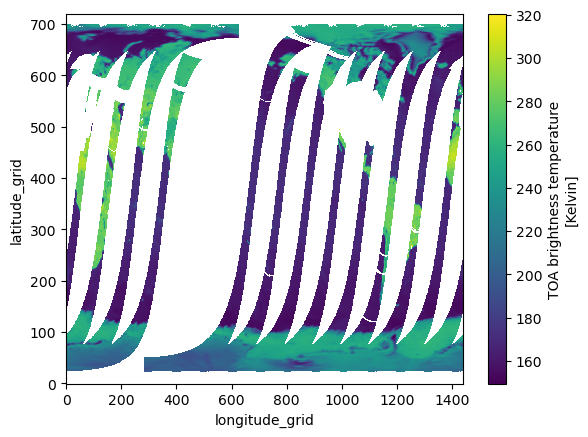

In [28]:
ws_ds.isel(polarization=0, frequency_band=0, look_direction=0, swath_sector=1).tbtoa.plot()

# I forgot what a pain in the ass this dataset is

In [40]:
# use my function to load the file and correct the coordinates
import sys
sys.path.append("../..")
from src.processing import windsat_datacube
ws_ds= windsat_datacube(r"../../data/raw/daily_Windsat")
ws_ds

<xarray.Dataset>
Dimensions:         (day_number: 1, longitude_grid: 1440, latitude_grid: 720,
                     swath_sector: 2, frequency_band: 2, look_direction: 2,
                     polarization: 2)
Coordinates:
    lat             (latitude_grid) float32 dask.array<chunksize=(720,), meta=np.ndarray>
    lon             (longitude_grid) float32 dask.array<chunksize=(1440,), meta=np.ndarray>
  * day_number      (day_number) int32 253
Dimensions without coordinates: longitude_grid, latitude_grid, swath_sector,
                                frequency_band, look_direction, polarization
Data variables: (12/13)
    longitude       (day_number, longitude_grid) float32 dask.array<chunksize=(1, 1440), meta=np.ndarray>
    latitude        (day_number, latitude_grid) float32 dask.array<chunksize=(1, 720), meta=np.ndarray>
    node            (day_number, swath_sector) int32 dask.array<chunksize=(1, 2), meta=np.ndarray>
    frequency_vpol  (day_number, frequency_band) float32 dask.array<chunksize=(1, 2), meta=np.ndarray>
    frequency_hpol  (day_number, frequency_band) float32 dask.array<chunksize=(1, 2), meta=np.ndarray>
    eia_nominal     (day_number, frequency_band) float32 dask.array<chunksize=(1, 2), meta=np.ndarray>
    ...              ...
    eaa             (day_number, frequency_band, latitude_grid, longitude_grid, look_direction, swath_sector) float32 dask.array<chunksize=(1, 2, 720, 1440, 2, 2), meta=np.ndarray>
    eia             (day_number, frequency_band, latitude_grid, longitude_grid, look_direction, swath_sector) float32 dask.array<chunksize=(1, 2, 720, 1440, 2, 2), meta=np.ndarray>
    tbtoa           (day_number, polarization, frequency_band, latitude_grid, longitude_grid, look_direction, swath_sector) float32 dask.array<chunksize=(1, 2, 2, 720, 1440, 2, 2), meta=np.ndarray>
    quality_flag    (day_number, latitude_grid, longitude_grid, look_direction, swath_sector) int32 dask.array<chunksize=(1, 720, 1440, 2, 2), meta=np.ndarray>
    surtep_ERA5     (day_number, latitude_grid, longitude_grid, swath_sector) float32 dask.array<chunksize=(1, 720, 1440, 2), meta=np.ndarray>
    airtep_ERA5     (day_number, latitude_grid, longitude_grid, swath_sector) float32 dask.array<chunksize=(1, 720, 1440, 2), meta=np.ndarray>
Attributes: (12/72)
    Conventions:                            CF-1.7
    title:                                  RSS WindSat TOA Brightness Temper...
    version:                                V01.0
    summary:                                The dataset contains RSS WindSat ...
    references:                              [1] T. Meissner et al., Remote S...
    acknowledgement:                        Funded under NASA Grant 80NSSC21K...
    ...                                     ...
    Source_of_ancillary_IMERG_rain_rate:    Huffman, G. et al.,  2019. NASA G...
    Source_of_ancillary_CCMP_wind:          Mears, C. et al., 2023.Remote Sen...
    Source_of_ancillary_ERA5:               ECMWF Reanalysis v5 (ERA5). https...
    Source_of_RSS_WindSat_AS_ECV:           https://www.remss.com/missions/wi...
    Source_of_ancillary_HYCOM_SSS:          Hybrid Coordinate Ocean Model, Gl...
    Source_of_WindSat_L1C_TB:               T. Meissner et al., Remote Sensin...

(35.0, 45.0)

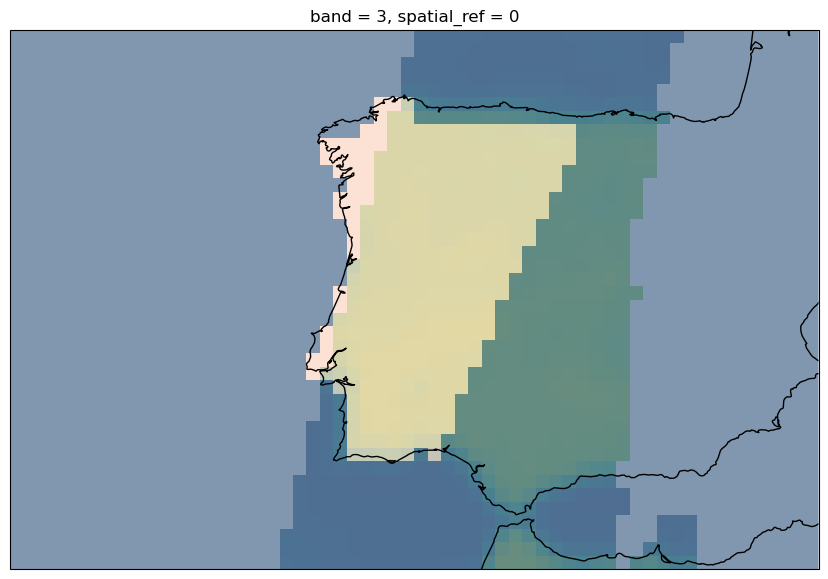

In [58]:
_, ax = plt.subplots(1,1, figsize=(14,7), subplot_kw={"projection": ccrs.PlateCarree()})

ws_ds.isel(polarization=0, frequency_band=0, look_direction=0, swath_sector=1).tbtoa.sortby(["lat","lon"]).plot(x="lon", y="lat", ax=ax, alpha=0.5, add_colorbar=False)
rp_ds.sel(band=3).band_data.plot(ax=ax, alpha=0.5,add_colorbar=False)
ax.coastlines("10m")
x_lims = (-15,0)
y_lims = (35,45)
ax.set_xlim(x_lims[0], x_lims[1])
ax.set_ylim(y_lims[0], y_lims[1])

## Now check that the fields are correct

In [ ]:
rp_ds.sel(band=3).band_data

<xarray.DataArray 'band_data' (y: 720, x: 1440)>
[1036800 values with dtype=float32]
Coordinates:
    band         int32 3
  * x            (x) float64 -179.9 -179.6 -179.4 -179.1 ... 179.4 179.6 179.9
  * y            (y) float64 89.88 89.62 89.38 89.12 ... -89.38 -89.62 -89.88
    spatial_ref  int32 ...
Attributes:
    TIFFTAG_DOCUMENTNAME:      Y:/data/LPDR_v2/GeoTIFF/2017/AMSRU_Mland_20173...
    TIFFTAG_IMAGEDESCRIPTION:  IDL TIFF file
    TIFFTAG_SOFTWARE:          IDL 8.7.2, Harris Geospatial Solutions, Inc.
    TIFFTAG_DATETIME:          2021:03:16 22:40:16
    TIFFTAG_XRESOLUTION:       100
    TIFFTAG_YRESOLUTION:       100
    TIFFTAG_RESOLUTIONUNIT:    2 (pixels/inch)
    AREA_OR_POINT:             Area
    long_name:                 (None, None, None, None, None, None, None, 'La...